In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
import cv2

## Tấn Hiệp – Demo 5: Xoay ảnh (warping ngược, nội suy)

In [2]:
def tao_ban_co(kich_thuoc=200, o=25, sang=220, toi=60):
    y, x = np.indices((kich_thuoc, kich_thuoc))
    ban_co = np.where((x // o + y // o) % 2 == 0, sang, toi)
    return ban_co.astype(np.uint8)


def ma_tran_xoay(goc_do, cx, cy):
    # góc dương = xoay ngược chiều kim đồng hồ (trục y của ảnh hướng xuống)
    t = np.deg2rad(goc_do)
    c, s = np.cos(t), np.sin(t)

    T_ve_goc = np.array([[1, 0, -cx],
                         [0, 1, -cy],
                         [0, 0, 1]])
    R = np.array([[c, s, 0],
                  [-s, c, 0],
                  [0, 0, 1]])
    T_ve_tam = np.array([[1, 0, cx],
                         [0, 1, cy],
                         [0, 0, 1]])

    return T_ve_tam @ R @ T_ve_goc


ban_co = tao_ban_co()
h, w = ban_co.shape
cx, cy = (w - 1) / 2, (h - 1) / 2

M = ma_tran_xoay(30, cx, cy)
print("Ma trận xoay 30°:\n", np.round(M, 3))
print("Tâm sau khi xoay:", M @ [cx, cy, 1])   # phải giữ nguyên (99.5, 99.5, 1)

Ma trận xoay 30°:
 [[  0.866   0.5   -36.42 ]
 [ -0.5     0.866  63.08 ]
 [  0.      0.      1.   ]]
Tâm sau khi xoay: [99.5 99.5  1. ]


In [3]:
def lay_gan_nhat(anh, x, y):
    h, w = anh.shape[:2]
    xi = np.round(x).astype(int)
    yi = np.round(y).astype(int)

    hop_le = (xi >= 0) & (xi < w) & (yi >= 0) & (yi < h)

    ket_qua = np.zeros(x.shape + anh.shape[2:], dtype=anh.dtype)
    ket_qua[hop_le] = anh[yi[hop_le], xi[hop_le]]
    return ket_qua


def lay_song_tuyen(anh, x, y):
    h, w = anh.shape[:2]
    anh = anh.astype(np.float64)

    hop_le = (x >= 0) & (x <= w - 1) & (y >= 0) & (y <= h - 1)

    x0 = np.floor(x).astype(int)
    y0 = np.floor(y).astype(int)
    a = x - x0          # khoảng cách tới cột bên trái
    b = y - y0          # khoảng cách tới hàng phía trên

    # kẹp chỉ số để không tràn mảng, điểm ngoài ảnh sẽ bị gán 0 ở dưới
    x0c, x1c = np.clip(x0, 0, w - 1), np.clip(x0 + 1, 0, w - 1)
    y0c, y1c = np.clip(y0, 0, h - 1), np.clip(y0 + 1, 0, h - 1)

    if anh.ndim == 3:   # ảnh màu: thêm 1 chiều để nhân với từng kênh
        a, b = a[..., None], b[..., None]

    gia_tri = ((1 - a) * (1 - b) * anh[y0c, x0c] +
               a * (1 - b) * anh[y0c, x1c] +
               (1 - a) * b * anh[y1c, x0c] +
               a * b * anh[y1c, x1c])

    gia_tri[~hop_le] = 0
    return np.clip(np.round(gia_tri), 0, 255).astype(np.uint8)


def xoay_anh(anh, goc_do, kieu="song_tuyen"):
    h, w = anh.shape[:2]
    M = ma_tran_xoay(goc_do, (w - 1) / 2, (h - 1) / 2)
    M_nguoc = np.linalg.inv(M)

    # toạ độ của mọi pixel trong ảnh ĐÍCH
    y_dich, x_dich = np.indices((h, w))

    # warping ngược: pixel đích này lấy giá trị từ đâu trong ảnh nguồn?
    # (chính là M_nguoc @ [x, y, 1], viết ra từng hàng cho cả ảnh)
    x_nguon = M_nguoc[0, 0] * x_dich + M_nguoc[0, 1] * y_dich + M_nguoc[0, 2]
    y_nguon = M_nguoc[1, 0] * x_dich + M_nguoc[1, 1] * y_dich + M_nguoc[1, 2]

    if kieu == "gan_nhat":
        return lay_gan_nhat(anh, x_nguon, y_nguon)
    if kieu == "song_tuyen":
        return lay_song_tuyen(anh, x_nguon, y_nguon)
    raise ValueError("kieu phải là 'gan_nhat' hoặc 'song_tuyen'")

In [4]:
def xoay_xuoi(anh, goc_do):
    h, w = anh.shape[:2]
    M = ma_tran_xoay(goc_do, (w - 1) / 2, (h - 1) / 2)

    y, x = np.indices((h, w))
    xd = np.round(M[0, 0] * x + M[0, 1] * y + M[0, 2]).astype(int)
    yd = np.round(M[1, 0] * x + M[1, 1] * y + M[1, 2]).astype(int)

    hop_le = (xd >= 0) & (xd < w) & (yd >= 0) & (yd < h)
    ket_qua = np.zeros_like(anh)
    ket_qua[yd[hop_le], xd[hop_le]] = anh[y[hop_le], x[hop_le]]
    return ket_qua


goc = 30
anh_xuoi = xoay_xuoi(ban_co, goc)
anh_gan_nhat = xoay_anh(ban_co, goc, "gan_nhat")
anh_song_tuyen = xoay_anh(ban_co, goc, "song_tuyen")

vung_anh = xoay_anh(np.full_like(ban_co, 255), goc, "song_tuyen") == 255

for ten, anh in [("Warping xuôi", anh_xuoi),
                 ("Ngược + gần nhất", anh_gan_nhat),
                 ("Ngược + song tuyến", anh_song_tuyen)]:
    so_lo = np.sum(vung_anh & (anh == 0))
    print(f"{ten:20s}: {so_lo} lỗ")

Warping xuôi        : 4508 lỗ
Ngược + gần nhất    : 0 lỗ
Ngược + song tuyến  : 0 lỗ


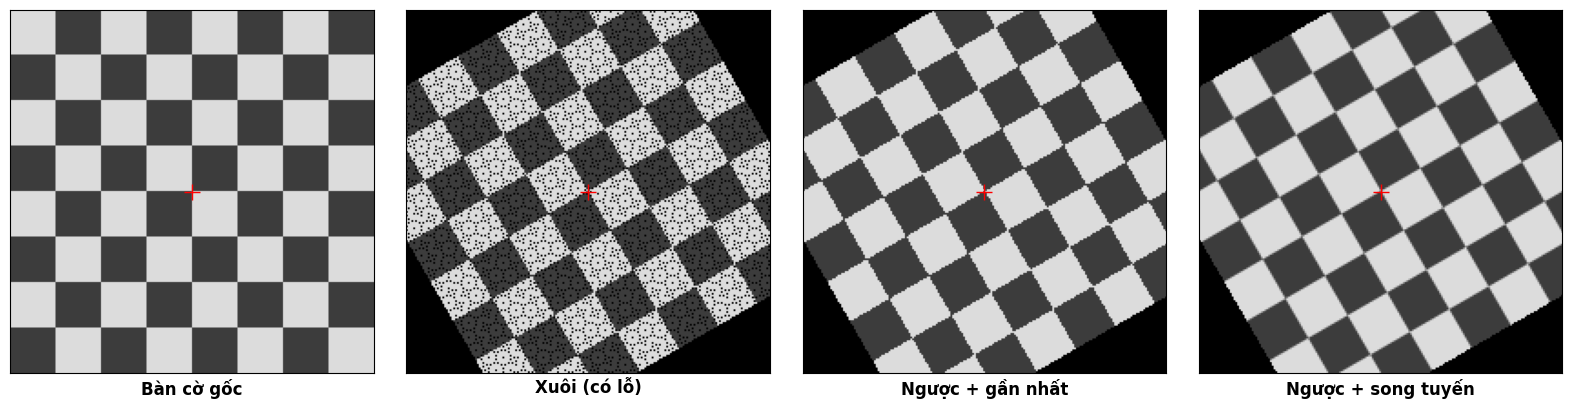

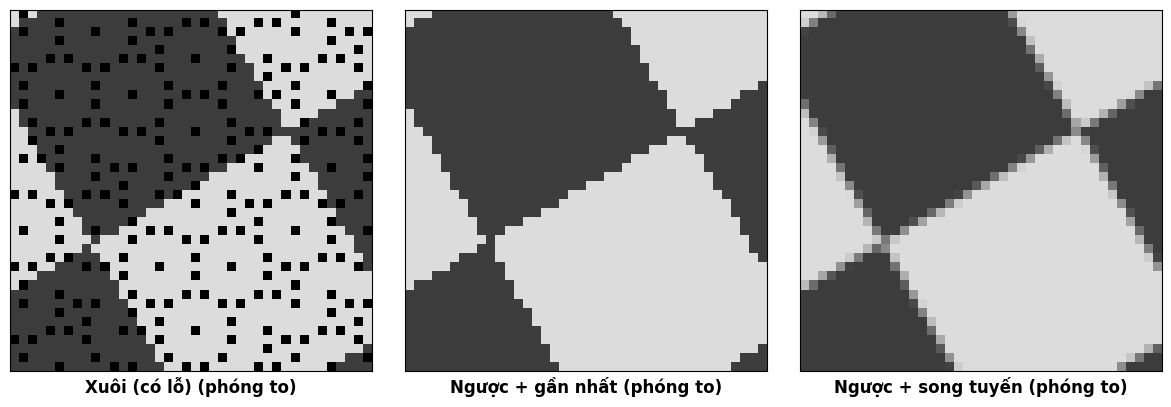

In [5]:
anh_list = [ban_co, anh_xuoi, anh_gan_nhat, anh_song_tuyen]
ten_list = ["Bàn cờ gốc", "Xuôi (có lỗ)", "Ngược + gần nhất", "Ngược + song tuyến"]

plt.figure(figsize=(16, 4))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(anh_list[i], cmap="gray", vmin=0, vmax=255)
    plt.plot(cx, cy, "r+", markersize=12)    # dấu + đỏ = tâm ảnh
    plt.xlabel(ten_list[i], fontsize=12, fontweight="bold")
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()

y1, y2, x1, x2 = 40, 80, 100, 140
plt.figure(figsize=(12, 4))
for i, (anh, ten) in enumerate(zip(anh_list[1:], ten_list[1:])):
    plt.subplot(1, 3, i + 1)
    plt.imshow(anh[y1:y2, x1:x2], cmap="gray", vmin=0, vmax=255,
               interpolation="nearest")
    plt.xlabel(ten + " (phóng to)", fontsize=12, fontweight="bold")
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()

In [6]:
xoay_90 = xoay_anh(ban_co, 90, "gan_nhat")
print("Xoay 90° == np.rot90:", np.array_equal(xoay_90, np.rot90(ban_co)))

M_cv = cv2.getRotationMatrix2D((cx, cy), goc, 1.0)
cv_gan_nhat = cv2.warpAffine(ban_co, M_cv, (w, h), flags=cv2.INTER_NEAREST)
cv_song_tuyen = cv2.warpAffine(ban_co, M_cv, (w, h), flags=cv2.INTER_LINEAR)
print("Ma trận của mình == OpenCV:", np.allclose(ma_tran_xoay(goc, cx, cy)[:2], M_cv))
print("Gần nhất - sai lệch TB:", np.mean(np.abs(anh_gan_nhat.astype(int) - cv_gan_nhat)))
print("Song tuyến - sai lệch TB:", np.mean(np.abs(anh_song_tuyen.astype(int) - cv_song_tuyen)))

ban_co_to = tao_ban_co(kich_thuoc=8 * h, o=8 * 25)
anh_chuan = cv2.resize(xoay_anh(ban_co_to, goc, "song_tuyen"), (w, h),
                       interpolation=cv2.INTER_AREA)

def sai_so(anh):
    return np.mean(np.abs(anh.astype(int) - anh_chuan)[vung_anh])

print("Sai số so với ảnh chuẩn - gần nhất  :", round(sai_so(anh_gan_nhat), 2))
print("Sai số so với ảnh chuẩn - song tuyến:", round(sai_so(anh_song_tuyen), 2))

Xoay 90° == np.rot90: True
Ma trận của mình == OpenCV: True
Gần nhất - sai lệch TB: 0.0
Song tuyến - sai lệch TB: 0.6021
Sai số so với ảnh chuẩn - gần nhất  : 2.86
Sai số so với ảnh chuẩn - song tuyến: 0.29


In [7]:
cv2.imwrite("../images/xoay_gan_nhat.png", anh_gan_nhat)
cv2.imwrite("../images/xoay_song_tuyen.png", anh_song_tuyen)

True

## KT3 – hough_multiscale